<a href="https://colab.research.google.com/github/AnjanMahapatra/Internship-project/blob/main/Crop_yeild_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NUM = ["average_rain_fall_mm_per_year", "avg_temp", "pesticides_tonnes"]
CAT = ["Item"]
TARGET = "hg/ha_yield"

# ------------- 1. DATA ------------
df = pd.read_csv("/content/drive/MyDrive/yield_df.csv")
df = df[df["Area"] == "India"].drop(columns=["Unnamed: 0", "Area"], errors="ignore")
print("India rows:", len(df))
df = df.drop_duplicates()
print("After removing duplicates:", len(df))
print("Unique (crop, year) pairs:", df.groupby(["Item", "Year"]).ngroups)
df = df.groupby(["Item", "Year"], as_index=False).mean(numeric_only=True)
df.to_csv("clean_india.csv", index=False)
print(df.describe().T, "\n")

# ------------- 2. EDA ---------------
corr = df[NUM + [TARGET]].corr()
print("Correlation with yield:\n", corr[TARGET], "\n")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.savefig("fig_correlation.png", dpi=150); plt.close()

df.pivot(index="Year", columns="Item", values=TARGET).plot(figsize=(9, 5))
plt.ylabel("Yield (hg/ha)"); plt.title("Crop yield over time, India")
plt.tight_layout(); plt.savefig("fig_yield_trend.png", dpi=150); plt.close()

India rows: 4048
After removing duplicates: 3384
Unique (crop, year) pairs: 184
                               count          mean           std  \
Year                           184.0   2001.434783      7.083120   
hg/ha_yield                    184.0  80884.467391  96200.141667   
average_rain_fall_mm_per_year  184.0   1083.000000      0.000000   
pesticides_tonnes              184.0  48459.040000  15036.414909   
avg_temp                       184.0     26.051610      0.322065   

                                        min           25%           50%  \
Year                            1990.000000   1995.000000   2001.000000   
hg/ha_yield                     6553.000000  13704.750000  28124.000000   
average_rain_fall_mm_per_year   1083.000000   1083.000000   1083.000000   
pesticides_tonnes              14485.330000  37423.000000  46195.000000   
avg_temp                          25.460588     25.811111     25.988333   

                                         75%            max 

In [ ]:
# ------------- 3. MODELS -----------------
pre = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

models = {
    "Linear Regression": (LinearRegression(), {}),
    "KNN": (KNeighborsRegressor(), {"m__n_neighbors": [3, 5, 7, 11]}),
    "Random Forest": (RandomForestRegressor(random_state=42),
                      {"m__n_estimators": [100, 300], "m__max_depth": [None, 6, 12]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42),
                          {"m__n_estimators": [100, 200], "m__learning_rate": [0.05, 0.1],
                           "m__max_depth": [2, 3, 4]}),
}


def metrics(y, p):
    return (r2_score(y, p), mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p)))


def fit_tuned(name, est, grid, X, y, cv):
    pipe = Pipeline([("pre", clone(pre)), ("m", est)])
    if grid:
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="r2", n_jobs=-1)
        gs.fit(X, y)
        return gs.best_estimator_, gs.best_params_
    return pipe.fit(X, y), {}


X, y = df[NUM + CAT], df[TARGET]
rows, fitted = [], {}

In [ ]:
# --- Scenario A: random split (what the paper did -> optimistic / leaky)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
for name, (est, grid) in models.items():
    m, _ = fit_tuned(name, est, grid, Xtr, ytr, cv=5)
    r2, mae, rmse = metrics(yte, m.predict(Xte))
    rows.append(["Random split (paper style)", name, r2, mae, rmse])

# --- Scenario B: time-based split (realistic: predict future years)
train_mask = df["Year"] <= 2008
Xtr, ytr = X[train_mask], y[train_mask]
Xte, yte = X[~train_mask], y[~train_mask]
print(f"Time split -> train {len(Xtr)} rows (<=2008), test {len(Xte)} rows (>2008)")
for name, (est, grid) in models.items():
    # TimeSeriesSplit needs ordered data: sort by year
    order = df.loc[train_mask, "Year"].argsort().values
    m, best = fit_tuned(name, est, grid, Xtr.iloc[order], ytr.iloc[order], cv=TimeSeriesSplit(4))
    r2, mae, rmse = metrics(yte, m.predict(Xte))
    rows.append(["Time split (honest)", name, r2, mae, rmse])
    fitted[name] = m
    print(name, best)

# --- Baseline: predict each crop's training mean (no weather at all)
base_pred = Xte["Item"].map(ytr.groupby(Xtr["Item"]).mean())
r2, mae, rmse = metrics(yte, base_pred)
rows.append(["Time split (honest)", "Baseline: crop mean only", r2, mae, rmse])

Time split -> train 144 rows (<=2008), test 40 rows (>2008)
Linear Regression {}
KNN {'m__n_neighbors': 3}
Random Forest {'m__max_depth': None, 'm__n_estimators': 100}
Gradient Boosting {'m__learning_rate': 0.1, 'm__max_depth': 2, 'm__n_estimators': 200}


In [ ]:
# --- Scenario C: time split + last year's yield as a feature (typical forecasting setup)
df = df.sort_values(["Item", "Year"])
df["prev_yield"] = df.groupby("Item")[TARGET].shift(1)
dfl = df.dropna(subset=["prev_yield"])
NUM_L = NUM + ["prev_yield"]
pre_l = ColumnTransformer([("num", StandardScaler(), NUM_L), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
mask = dfl["Year"] <= 2008
for name, (est, grid) in models.items():
    pipe = Pipeline([("pre", clone(pre_l)), ("m", clone(est))])
    Xl, yl = dfl[NUM_L + CAT], dfl[TARGET]
    if grid:
        gs = GridSearchCV(pipe, grid, cv=3, scoring="r2", n_jobs=-1).fit(Xl[mask], yl[mask])
        pipe = gs.best_estimator_
    else:
        pipe.fit(Xl[mask], yl[mask])
    r2, mae, rmse = metrics(yl[~mask], pipe.predict(Xl[~mask]))
    rows.append(["Time split + lag feature", name, r2, mae, rmse])

res = pd.DataFrame(rows, columns=["Scenario", "Model", "R2", "MAE (hg/ha)", "RMSE (hg/ha)"])
res.to_csv("results.csv", index=False)
print("\n", res.round(3).to_string(index=False))


                   Scenario                    Model    R2  MAE (hg/ha)  RMSE (hg/ha)
Random split (paper style)        Linear Regression 0.960    12813.139     22164.183
Random split (paper style)                      KNN 0.799    24339.751     49511.259
Random split (paper style)            Random Forest 0.964    10790.219     20806.356
Random split (paper style)        Gradient Boosting 0.973    10289.715     18254.109
       Time split (honest)        Linear Regression 0.897    20625.991     37641.678
       Time split (honest)                      KNN 0.417    64920.008     89773.227
       Time split (honest)            Random Forest 0.891    19627.236     38810.899
       Time split (honest)        Gradient Boosting 0.887    20072.908     39458.936
       Time split (honest) Baseline: crop mean only 0.895    20470.457     38054.575
  Time split + lag feature        Linear Regression 0.991     6414.161     11049.791
  Time split + lag feature                      KNN 0.855    27

In [ ]:
# --------------- 4. PLOTS ----------------
piv = res.pivot(index="Model", columns="Scenario", values="R2")
piv.plot(kind="bar", figsize=(9, 5)); plt.ylabel("R2"); plt.axhline(0, color="k", lw=0.5)
plt.title("Model R2 under different evaluation schemes"); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig("fig_model_comparison.png", dpi=150); plt.close()

cand = res[(res.Scenario == "Time split (honest)") & (res.Model.isin(fitted.keys()))]
best_name = cand.sort_values("R2").iloc[-1]["Model"]
best = fitted[best_name]
pred = best.predict(Xte)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(yte, pred, alpha=0.7)
lim = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
plt.plot(lim, lim, "r--"); plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title(f"{best_name}: actual vs predicted (2009-2013)")
plt.tight_layout(); plt.savefig("fig_actual_vs_pred.png", dpi=150); plt.close()

pi = permutation_importance(best, Xte, yte, n_repeats=30, random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=NUM + CAT).sort_values()
imp.plot(kind="barh", figsize=(7, 4)); plt.title("Permutation importance (test set)")
plt.tight_layout(); plt.savefig("fig_importance.png", dpi=150); plt.close()
print("\nFeature importance:\n", imp)


Feature importance:
 pesticides_tonnes               -1.668755e-03
average_rain_fall_mm_per_year    0.000000e+00
avg_temp                         3.862725e-07
Item                             1.505371e+00
dtype: float64


In [ ]:
# --------------- 5. SAVE FINAL MODEL -----------------
final = Pipeline([("pre", pre), ("m", models[best_name][0])])
final.set_params(**{k: v for k, v in best.get_params().items() if k.startswith("m__")})
final.fit(X, y)
joblib.dump(final, "model.joblib")
joblib.dump({"items": sorted(df["Item"].unique()),
             "ranges": {c: (float(df[c].min()), float(df[c].max())) for c in NUM}},
            "meta.joblib")
print("\nSaved model.joblib using", best_name)


Saved model.joblib using Linear Regression


In [ ]:
import joblib, pandas as pd, ipywidgets as w
from IPython.display import display

model = joblib.load("model.joblib")
meta = joblib.load("meta.joblib")
r = meta["ranges"]
rain = r["average_rain_fall_mm_per_year"][0]   # constant in the dataset

mid = lambda k: (r[k][0] + r[k][1]) / 2
crop = w.Dropdown(options=meta["items"], description="Crop")
temp = w.FloatSlider(value=mid("avg_temp"), min=r["avg_temp"][0], max=r["avg_temp"][1],
                     step=0.05, description="Temp °C", style={"description_width": "90px"})
pest = w.FloatSlider(value=mid("pesticides_tonnes"), min=r["pesticides_tonnes"][0],
                     max=r["pesticides_tonnes"][1], step=500, description="Pesticides (t)",
                     style={"description_width": "90px"})
dT = w.FloatSlider(value=1.0, min=-2, max=4, step=0.5, description="What-if ΔTemp",
                   style={"description_width": "90px"})
out = w.Output()

def predict(t):
    row = pd.DataFrame([{"Item": crop.value,
                         "average_rain_fall_mm_per_year": rain,
                         "avg_temp": t, "pesticides_tonnes": pest.value}])
    return float(model.predict(row)[0])

def update(_=None):
    base, new = predict(temp.value), predict(temp.value + dT.value)
    with out:
        out.clear_output()
        print(f"Predicted yield: {base:,.0f} hg/ha  (~{base/10000:.2f} t/ha)")
        print(f"What-if (+{dT.value}°C): {new:,.0f} hg/ha  ({(new-base)/base*100:+.1f}%)")
        print(f"Rainfall fixed at {rain:.0f} mm (constant in the dataset).")

for c in (crop, temp, pest, dT):
    c.observe(update, names="value")
display(crop, temp, pest, dT, out)
update()

Dropdown(description='Crop', options=('Cassava', 'Maize', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'S…

FloatSlider(value=26.123715170278636, description='Temp °C', max=26.78684210526316, min=25.460588235294118, st…

FloatSlider(value=44742.665, description='Pesticides (t)', max=75000.0, min=14485.330000000002, step=500.0, st…

FloatSlider(value=1.0, description='What-if ΔTemp', max=4.0, min=-2.0, step=0.5, style=SliderStyle(description…

Output()

fig_yield_trend.png


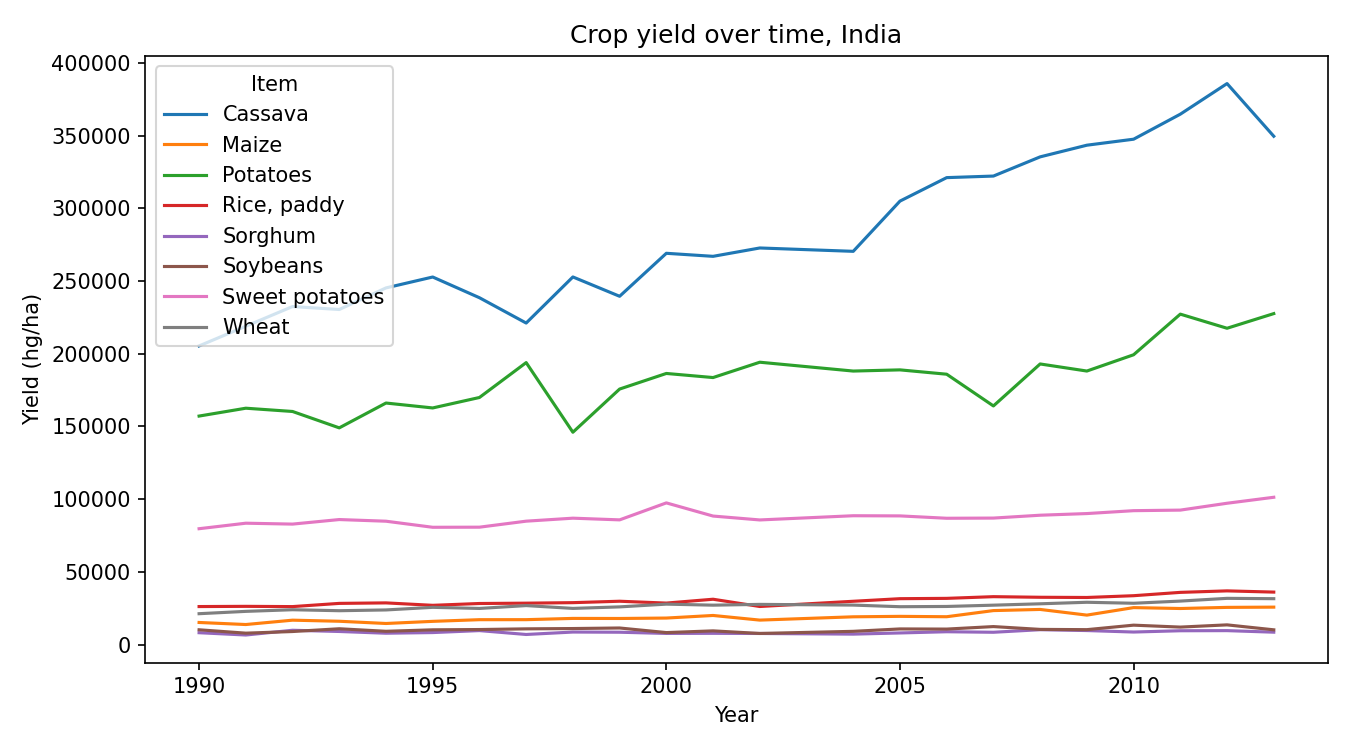

fig_correlation.png


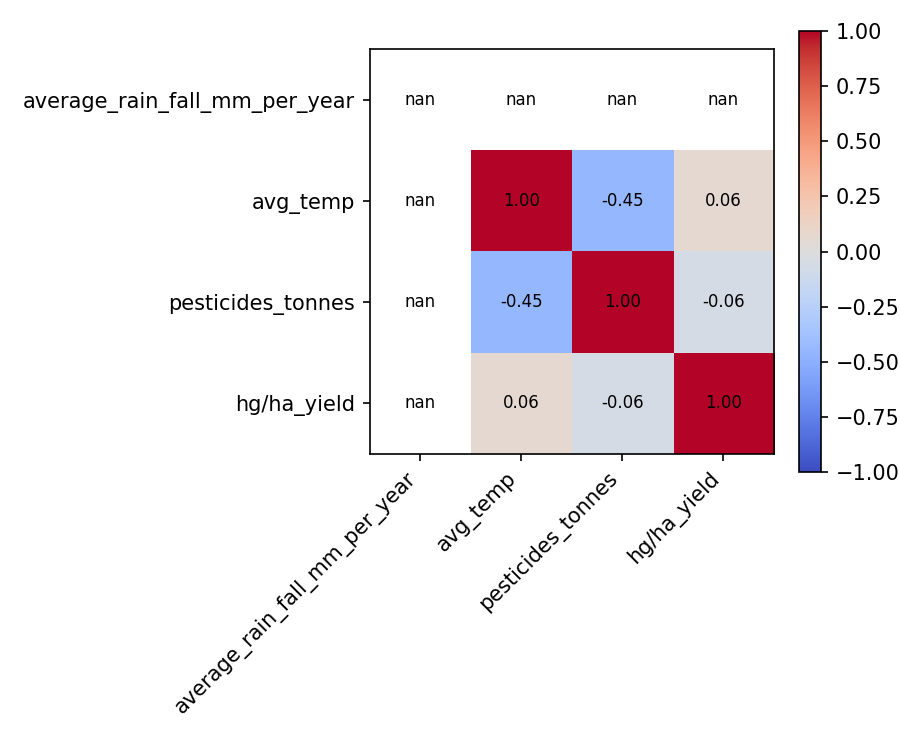

fig_importance.png


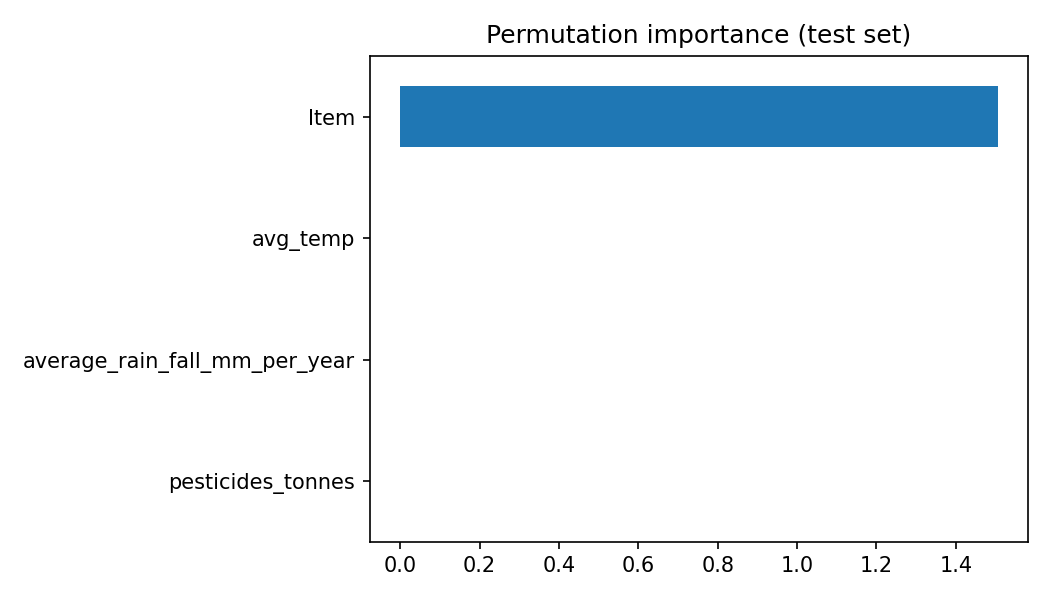

fig_model_comparison.png


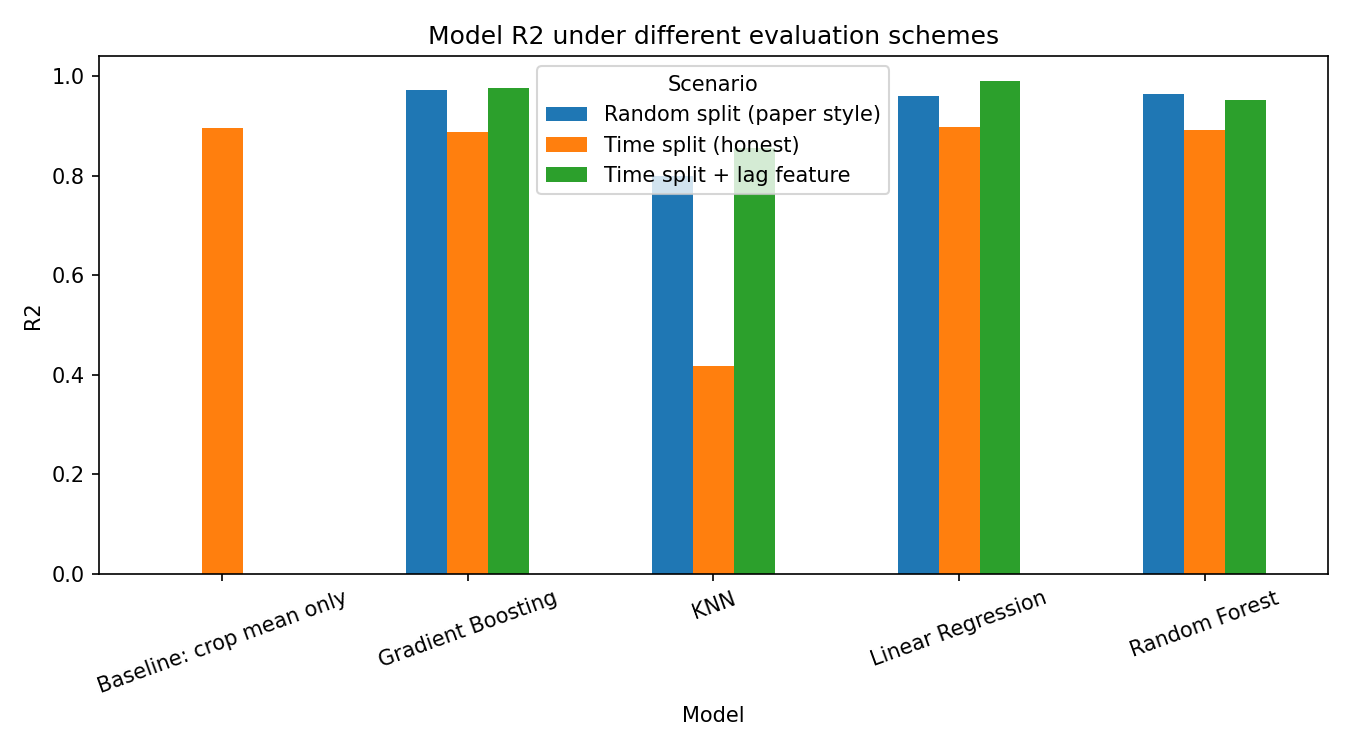

fig_actual_vs_pred.png


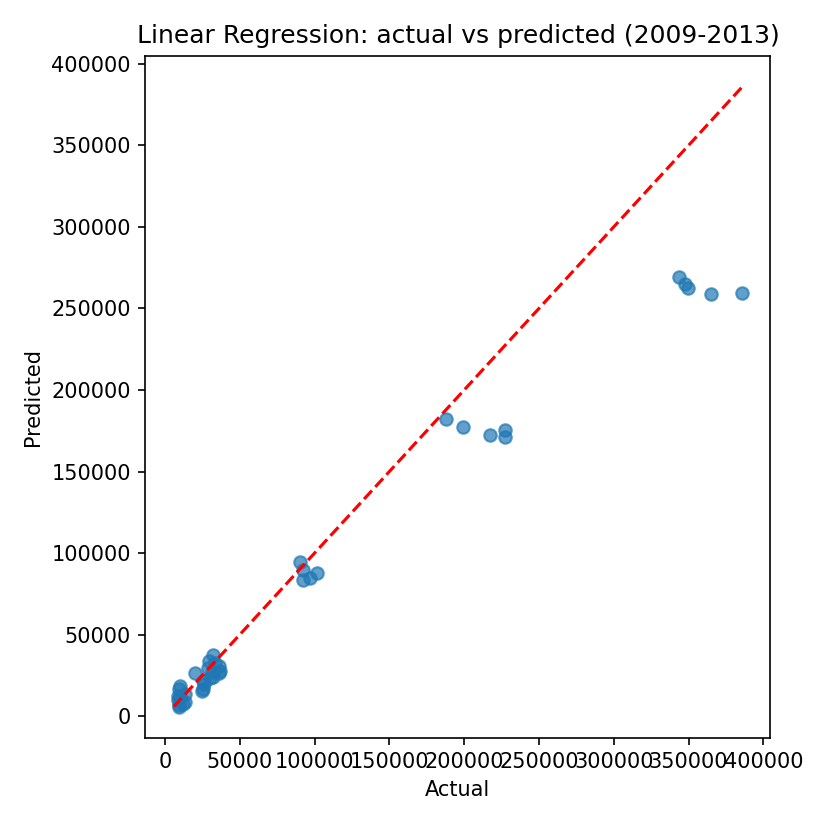

In [ ]:
from IPython.display import Image, display

figures = [
    "fig_yield_trend.png",
    "fig_correlation.png",
    "fig_importance.png",
    "fig_model_comparison.png",
    "fig_actual_vs_pred.png",
]
for f in figures:
    print(f)
    display(Image(f, width=600))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

res = pd.read_csv("results.csv")
piv = res.pivot(index="Model", columns="Scenario", values="R2")

ax = piv.plot(kind="bar", figsize=(10, 5), width=0.8)
ax.set_ylabel("R² score")
ax.set_title("Model R² under different evaluation schemes")
ax.axhline(0, color="black", linewidth=0.5)
ax.axhline(0.895, color="red", linestyle="--", linewidth=1, label="Crop-mean baseline (0.895)")
ax.legend(loc="lower right")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("fig_model_comparison_v2.png", dpi=200)
plt.show()